# HanuAi ML Assessment: Task 2, Advanced EDA and Text Mining

**Data:** 1,000 vehicle infotainment (radio, display, camera, USB) warranty events, with three free-text fields written by the customer and the technician.

**Goal:** turn the free text into structured tags, group the events into issue types and natural failure clusters, and give stakeholders clear, evidence-based actions.

**How to read this notebook:** every step has a short note in plain words before the code. The code itself has no hash comments; each function has a docstring that explains what it does.

**How to run:** keep the data file at `data/Hanuai_task2_assignment.csv`, open this notebook from the `task2_eda_text_mining` folder and choose Run All.

## 1. Setup and load the data
We use pandas for tables, matplotlib and seaborn for charts, scipy for a statistical test, and scikit-learn for TF-IDF and K-Means. Random seeds are fixed so results repeat.

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

DATA_PATH = Path("data/Hanuai_task2_assignment.csv")
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA_PATH)
df = raw.copy()
print("rows, columns:", df.shape)
df.head(3)

rows, columns: (1000, 20)


,Event id,Opened date,CAUSAL_VERBATIM,CORRECTION_VERBATIM,CUSTOMER_VERBATIM,BUILD_DATE,BUILD_PLANT_DESC,CAUSAL_CD_DESC,COMPLAINT_CD_DESC,IN_USE_DATE,MAKE,MODEL,MODLYR,PLANT,Trigger,Failure Component,Failure Condition,Additional Context,Fix Component,Fix Condition
0,D-14801,9/17/2019,unable to duplicate the concern at this time radio and display both working ...,"waiting for techline engineering response, attempted to reprogram the radio ...",Customer reports that radio and screen is intermittantly inop Inspect and ad...,2019-08-14T00:00:00.000Z,Flint,Module/Component-No/Incorrect Communication,Audio/Entertainment/Navigation - Other issues,2019-09-10T00:00:00.000Z,NovaSprint,AeroSpecter,2020,FLT,['No Additional Functionality'],"['Audio Unit', 'Display']","['Controls Irresponsive', 'Black Screen']",['No Additional Context'],"['Radio', 'SPS']","['Replaced', 'Programmed']"
1,D-14869,7/6/2020,upon inspection radio screen was found to be blank with no sound . scanned f...,and ground at radio as stated in service info . verified test light lights b...,RADIO IS INOPERABLE CHECK AND ADVISE,2019-08-16T00:00:00.000Z,Fort Wayne,Module/Component-Shorted,Audio/Entertainment/Navigation - Other issues,2020-03-26T00:00:00.000Z,NebulaCruiser,StellarGlide,2020,FTW,['No Additional Functionality'],"['Radio', 'Display', 'Radio']","['Inoperative', 'Black Screen', 'No Sound']",['No Additional Context'],"['Radio', 'USB']","['Replaced', 'Programmed']"
2,D-14555,1/9/2020,Scanned found no codes checked for bulletins found none checked for updates ...,radio module internal failure,CUSTOMER STATES RADIO SCREEN AND ONSTAR KEEPS ATTEMPTING TO CONNECT TO WIFI ...,2019-08-06T00:00:00.000Z,Flint,Module/Component-Worn/Stripped,Audio/Entertainment/Navigation - Other issues,2019-11-29T00:00:00.000Z,ThunderVolt,HyperFury X,2020,FLT,['No Additional Functionality'],"['Display', 'OnStar', 'Radio Module']","['Inoperative', 'Inoperative', 'Internal Fault']",['No Additional Context'],['Radio'],['Replaced']


## 2. Data assessment
First we look at the schema, missing values, duplicates and odd values before changing anything.

In [2]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1),
    "unique_values": df.nunique(),
})
schema

,dtype,missing,missing_pct,unique_values
Event id,str,0,0.0,1000
Opened date,str,0,0.0,397
CAUSAL_VERBATIM,str,1,0.1,944
CORRECTION_VERBATIM,str,0,0.0,952
CUSTOMER_VERBATIM,str,0,0.0,990
BUILD_DATE,str,0,0.0,37
BUILD_PLANT_DESC,str,0,0.0,8
CAUSAL_CD_DESC,str,3,0.3,38
COMPLAINT_CD_DESC,str,0,0.0,9
IN_USE_DATE,str,1,0.1,285


In [3]:
print("fully duplicated rows:", df.duplicated().sum())
print("duplicated event ids:", df["Event id"].duplicated().sum())
same_text = df.duplicated(["CUSTOMER_VERBATIM", "MODEL", "Opened date"], keep=False).sum()
print("rows sharing customer text + model + opened date:", same_text)
print()
print("model year values:", df["MODLYR"].unique())
print("plant code to plant name is one-to-one:", (pd.crosstab(df["PLANT"], df["BUILD_PLANT_DESC"]) > 0).sum().max() == 1)
print()
print("complaint codes as stored (repr shows hidden characters):")
print(df["COMPLAINT_CD_DESC"].map(repr).value_counts().to_string())

fully duplicated rows: 0
duplicated event ids: 0
rows sharing customer text + model + opened date: 0

model year values: [2020]
plant code to plant name is one-to-one: True

complaint codes as stored (repr shows hidden characters):
COMPLAINT_CD_DESC
'Audio/Entertainment/Navigation - Audio'                          337
'Audio/Entertainment/Navigation - Other issues'                   263
'Audio/Entertainment/Navigation - Communication'                  194
'Audio/Entertainment/Navigation - Video'                          103
'Features/Controls/Displays - Other issues'                        47
'Audio/Entertainment/Navigation - Navigation'                      32
'Features/Controls/Displays - Gauges/Warning Lights'               12
'\xa0Audio/Entertainment/Navigation\xa0-\xa0Abnormal\xa0Noise'     11
'Features/Controls/Displays - Odometer'                             1


**What we found**

* No duplicate event ids and no fully duplicated rows. A few rows share customer text, model and date; they are separate events, so we keep them.
* `Trigger`, `Failure Component`, `Failure Condition`, `Additional Context`, `Fix Component` and `Fix Condition` are empty for 995 rows. They are not real gaps: only 5 rows carry them, as worked examples of the tags we are asked to extract. We will fill them for all 1,000 rows in section 6.
* `CAUSAL_CD_DESC` is missing in 3 rows, `CAUSAL_VERBATIM` in 1 row and `IN_USE_DATE` in 1 row. These are real gaps and get a documented fix below.
* `MODLYR` is 2020 for every row, so it carries no information.
* The complaint code `Abnormal Noise` is stored with hidden non-breaking spaces, so it would not match a normal string.
* Dates come in two formats: `m/d/yyyy` and ISO timestamps.

## 3. Data cleaning
Each change is small and recorded in a flag column so nothing is silently altered.

In [4]:
df["COMPLAINT_CD_DESC"] = (
    df["COMPLAINT_CD_DESC"]
    .str.replace("\xa0", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df["opened"] = pd.to_datetime(df["Opened date"], format="%m/%d/%Y")
df["built"] = pd.to_datetime(df["BUILD_DATE"], utc=True).dt.tz_localize(None)
df["in_use"] = pd.to_datetime(df["IN_USE_DATE"], utc=True).dt.tz_localize(None)

median_gap_days = int((df["in_use"] - df["built"]).dt.days.median())
df["in_use_imputed"] = df["in_use"].isna()
fill_dates = df["built"] + pd.to_timedelta(median_gap_days, unit="D")
df["in_use"] = df["in_use"].fillna(fill_dates)

df["causal_code_missing"] = df["CAUSAL_CD_DESC"].isna()
df["CAUSAL_CD_DESC"] = df["CAUSAL_CD_DESC"].fillna("Unknown")
df["CAUSAL_VERBATIM"] = df["CAUSAL_VERBATIM"].fillna("")

parts = df["CAUSAL_CD_DESC"].str.split("-", n=1, expand=True)
df["causal_group"] = parts[0].str.strip()
df["causal_detail"] = parts[1].fillna("Unknown").str.strip()

df["days_build_to_in_use"] = (df["in_use"] - df["built"]).dt.days
df["days_in_service"] = (df["opened"] - df["in_use"]).dt.days
df["days_since_build"] = (df["opened"] - df["built"]).dt.days
df["opened_before_in_use"] = df["days_in_service"] < 0
df["open_month"] = df["opened"].dt.to_period("M").dt.to_timestamp()

print("median build-to-in-use gap used to fill the missing in-use date:", median_gap_days, "days")
print("rows where the claim was opened BEFORE the in-use date:", int(df["opened_before_in_use"].sum()))
print("claims opened between", df["opened"].min().date(), "and", df["opened"].max().date())
print("all vehicles built between", df["built"].min().date(), "and", df["built"].max().date())

median build-to-in-use gap used to fill the missing in-use date: 91 days
rows where the claim was opened BEFORE the in-use date: 76
claims opened between 2019-08-27 and 2021-06-01
all vehicles built between 2019-08-01 and 2019-09-07


**Cleaning decisions**

* Missing `IN_USE_DATE` (1 row): filled with build date plus the median build-to-in-use gap, and flagged in `in_use_imputed`.
* Missing `CAUSAL_CD_DESC` (3 rows): set to `Unknown`, flagged. Missing `CAUSAL_VERBATIM` (1 row): set to empty text; the customer text is still mined.
* `CAUSAL_CD_DESC` is split into a group (for example `Module/Component`) and a detail (for example `Shorted`).
* **76 claims were opened before the vehicle's recorded in-use date.** These could be pre-delivery fixes or date entry errors. We keep them but flag them (`opened_before_in_use`) and leave them out of time-in-service statistics.
* **Every vehicle was built in one five-week window (Aug to early Sep 2019).** All claims are therefore from one build cohort, which makes time-in-service comparisons clean.

## 4. Statistical analysis and distributions
We pick the columns a stakeholder cares about: where and what was built (plant, make, model), what the customer complained about, the coded cause, and how long the vehicle had been in service when it failed.

In [5]:
num_cols = ["days_build_to_in_use", "days_in_service", "days_since_build"]
valid = df[~df["opened_before_in_use"]]
summary = pd.DataFrame({
    "mean": valid[num_cols].mean(),
    "median": valid[num_cols].median(),
    "std": valid[num_cols].std(),
    "min": valid[num_cols].min(),
    "max": valid[num_cols].max(),
}).round(1)
summary

,mean,median,std,min,max
days_build_to_in_use,110.4,84.5,89.7,1,526
days_in_service,241.7,228.0,161.0,0,615
days_since_build,352.0,350.0,158.5,26,665


In [6]:
df["customer_len"] = df["CUSTOMER_VERBATIM"].str.len()
df["causal_len"] = df["CAUSAL_VERBATIM"].str.len()
df["correction_len"] = df["CORRECTION_VERBATIM"].str.len()
df[["customer_len", "causal_len", "correction_len"]].describe().round(1)

,customer_len,causal_len,correction_len
count,1000.0,1000.0,1000.0
mean,100.4,140.1,179.8
std,80.9,182.9,222.8
min,5.0,0.0,8.0
25%,49.0,31.0,47.0
50%,79.0,77.0,97.5
75%,125.0,176.0,230.2
max,799.0,1890.0,1888.0


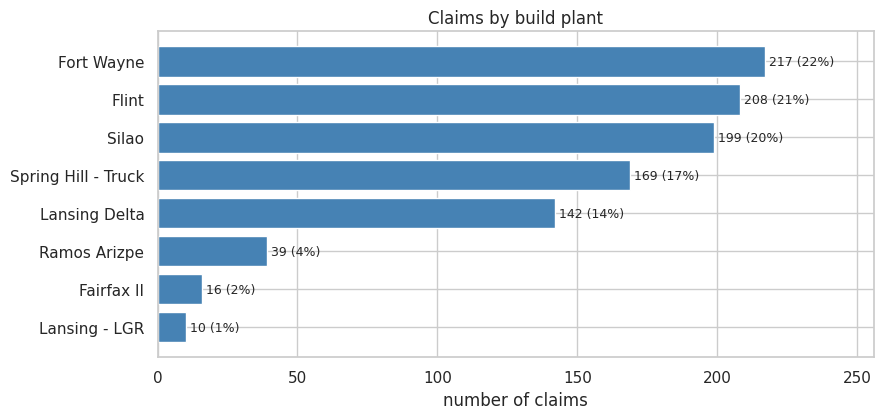

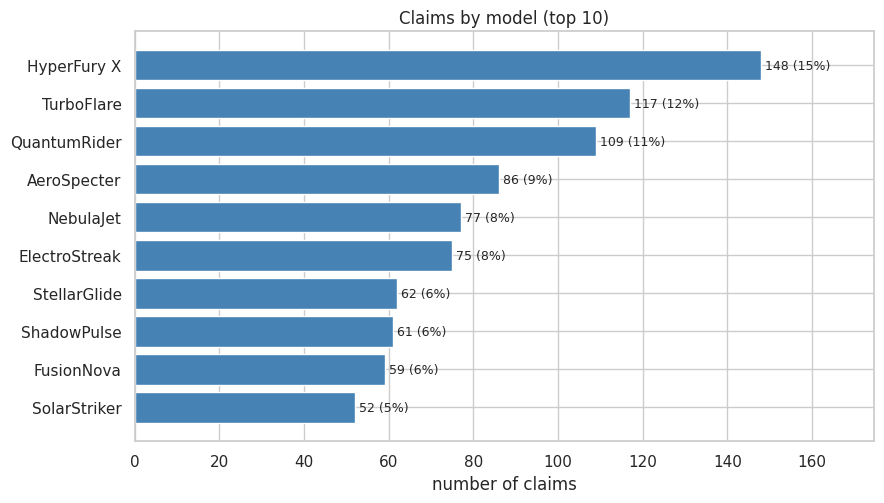

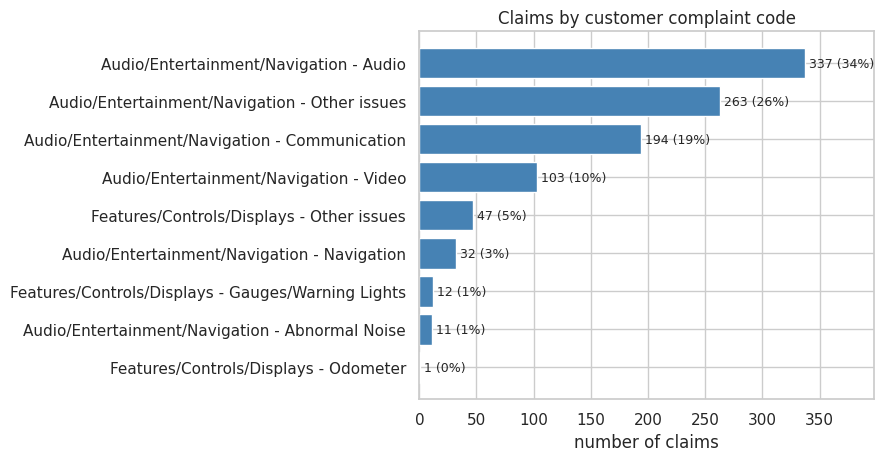

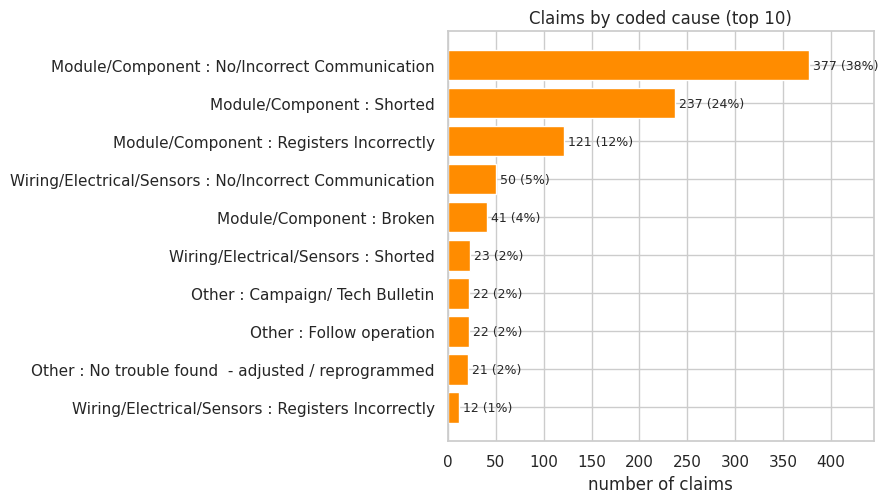

In [7]:
def bar_counts(series, title, fname, top=None, color="steelblue"):
    """Draw a horizontal bar chart of value counts, with the count and share printed on each bar, and save it."""
    counts = series.value_counts()
    if top:
        counts = counts.head(top)
    fig, ax = plt.subplots(figsize=(9, max(3, 0.42 * len(counts) + 1)))
    ax.barh(counts.index[::-1], counts.values[::-1], color=color)
    total = len(series)
    for i, v in enumerate(counts.values[::-1]):
        ax.text(v, i, f" {v} ({v / total:.0%})", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("number of claims")
    ax.set_xlim(0, counts.max() * 1.18)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150)
    plt.show()
    return counts


_ = bar_counts(df["BUILD_PLANT_DESC"], "Claims by build plant", "01_plant.png")
_ = bar_counts(df["MODEL"], "Claims by model (top 10)", "02_model.png", top=10)
_ = bar_counts(df["COMPLAINT_CD_DESC"], "Claims by customer complaint code", "03_complaint.png")
_ = bar_counts(df["causal_group"] + " : " + df["causal_detail"], "Claims by coded cause (top 10)", "04_causal.png", top=10, color="darkorange")

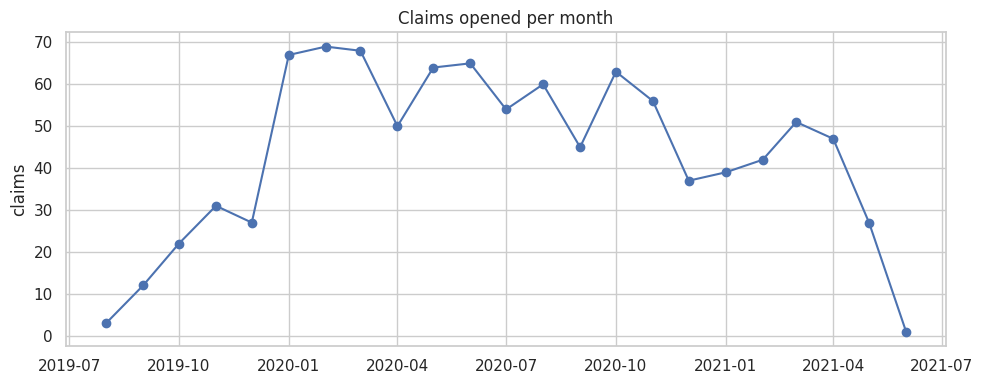

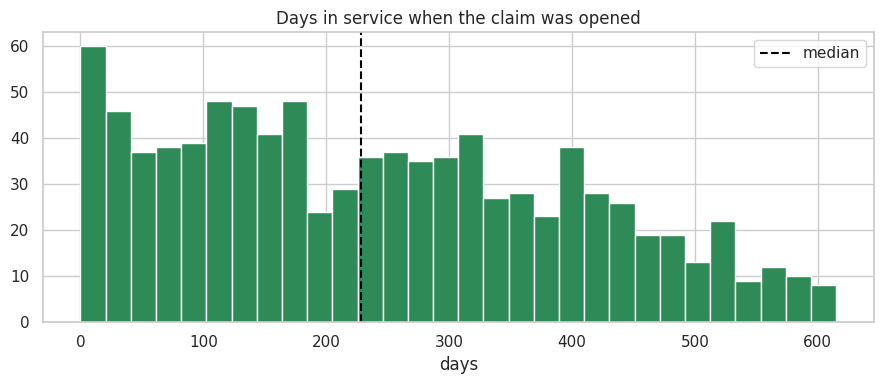

claims per month, Dec 2019: 27  Jan 2020: 67
average per month before Jan 2020 (Oct to Dec 2019): 26.7
average per month Jan to Dec 2020: 58.2


In [8]:
monthly = df.groupby("open_month").size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Claims opened per month")
ax.set_ylabel("claims")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_monthly.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(valid["days_in_service"], bins=30, color="seagreen")
ax.axvline(valid["days_in_service"].median(), color="black", linestyle="--", label="median")
ax.set_title("Days in service when the claim was opened")
ax.set_xlabel("days")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "06_days_in_service.png", dpi=150)
plt.show()

print("claims per month, Dec 2019:", int(monthly.get(pd.Timestamp("2019-12-01"), 0)), " Jan 2020:", int(monthly.get(pd.Timestamp("2020-01-01"), 0)))
print("average per month before Jan 2020 (Oct to Dec 2019):", round(monthly["2019-10":"2019-12"].mean(), 1))
print("average per month Jan to Dec 2020:", round(monthly["2020-01":"2020-12"].mean(), 1))

**What the statistics show**

* Time in service is wide: the typical (median) claim happens about 228 days after the vehicle enters service, with a standard deviation of about 161 days. Failures are not limited to the first weeks of ownership.
* Claims jump from 27 in December 2019 to 67 in January 2020 and stay high through mid 2020. The early months are low partly because the first vehicles had only just been delivered, so the ramp-up is expected. The plateau, not the jump, is the real signal.
* Three plants (Fort Wayne, Flint, Silao) account for about 62 percent of the claims in this data. We have no production volumes, so plant counts are **counts, not failure rates**. We avoid ranking plants by raw count and use mix comparisons later instead.

## 5. Free text fields
Three columns contain unstructured narrative:

| Column | Written by | Typical content |
|---|---|---|
| `CUSTOMER_VERBATIM` | service advisor, quoting the customer | the symptom |
| `CAUSAL_VERBATIM` | technician | the confirmed cause |
| `CORRECTION_VERBATIM` | technician | what was done to fix it |

Text quality problems we handle: upper and lower case mixed, words glued together by line breaks (for example `ANDRADIO`), numbers and codes that were redacted so only blank gaps remain (we found **no usable fault codes** in the text), a few rows in Spanish, and technician notes with long diagnostic steps that mention many parts that were only checked, not faulty.

Because of the last point we mine each field for what it is good at: symptoms from the customer text, cause from the causal text, and the repair from the correction text.

In [9]:
def clean_text(value):
    """Lower-case the text, replace odd spaces and collapse repeated spaces. Missing text becomes an empty string."""
    if pd.isna(value):
        return ""
    value = str(value).replace("\xa0", " ").lower()
    return re.sub(r"\s+", " ", value).strip()


df["cust"] = df["CUSTOMER_VERBATIM"].map(clean_text)
df["causal"] = df["CAUSAL_VERBATIM"].map(clean_text)
df["corr"] = df["CORRECTION_VERBATIM"].map(clean_text)
df[["cust", "causal", "corr"]].sample(3, random_state=1)

,cust,causal,corr
507,"customer states several radio issues.no xm at times, no sound at times, andr...",duplicated customer's concern. found (lost communication with radio) inhisto...,removed and replaced radio. programmed radiowith sps. warranty claim code .n...
818,cust states radio inop. no sound,"verify no sound from radio, follow si doc scan test - , contact tac - , inte...","replace radio - program, recheck operates as designed"
452,c/s when started the screen will switch frommain screen to user screen to na...,"inspect radio operation, concern is very intermittent and unable to verify, ...","clear all codes and recheck, ok, release toguest for evaluation"


## 6. Text mining: turning free text into tags
**Method:** a transparent, rule-based dictionary of regular expressions. Reasons: (1) it is explainable line by line, (2) no model download or API key is needed, (3) a domain expert can edit the dictionary, and (4) with only 5 labelled examples, a trained NER model would have too little to learn from. The limits are listed at the end of this section.

Tags follow the example format in the data file: `Failure Component`, `Failure Condition`, `Trigger`, `Additional Context`, `Fix Component`, `Fix Condition`.

In [10]:
FAILURE_COMPONENTS = {
    "Radio / Audio Unit": r"\bradio|head ?unit|audio unit|stereo|infotainment|receiver|\bhmi\b",
    "Display / Screen": r"screen|display|monitor|touch ?screen|\blcd\b",
    "Amplifier": r"\bamp\b|amplifier",
    "Speaker": r"speaker|tweeter|woofer",
    "Antenna": r"antenna",
    "USB Port": r"\busb\b",
    "Camera": r"camera|rear ?view|back ?up cam|\brvc\b",
    "Navigation": r"navigation|\bnav\b|\bgps\b",
    "Bluetooth / Phone": r"bluetooth|phone|hands ?free|carplay|android auto",
    "Satellite Radio": r"\bxm\b|sirius|satellite",
    "OnStar / Telematics": r"onstar|telematics|\btcu\b",
    "Controls / Knobs": r"knob|button|steering wheel control|\bswc\b|volume control|touch ?pad",
    "SD Card / Maps": r"sd card|memory card",
}
CAUSAL_ONLY_COMPONENTS = {
    "Wiring / Connector": r"harness|wiring|connector|cable|\bpin\b|terminal",
    "Other Module": r"tcicm|\bbcm\b|\becu\b|gateway|\bvim\b|\bicm\b",
}
CUSTOMER_CONDITIONS = {
    "Inoperative": r"\binop|inoperative|not working|no operation|doesn.?t work|does not work|dead|stopped working|quit working|not function|won.?t work",
    "Black Screen": r"black|blank|dark screen|screen off|pantalla",
    "No Sound": r"no sound|no audio|no volume|\bmute|silent|lost sound|sound out|audio out|no xm|cuts? out|cut in and out",
    "Intermittent": r"intermittent|at times|sometimes|randomly|come[s]? and go|on and off|time to time|occasionally|periodically",
    "Freezes / Locks Up": r"freez|froze|lock(s|ed)? up|hangs?\b|stuck|unresponsive|not respond|no response",
    "Reboots / Resets": r"reboot|\bresets?\b|restart|re-?start|turns? itself off|shuts? off|turns? off by itself",
    "Static / Noise / Distortion": r"static|noise|distort|crackl|buzz|\bpop|\bhum\b|whin|squeal|garbled|fuzz",
    "Communication Loss": r"communicat|network|lost connection|connectivity",
    "Won't Power On/Off": r"won.?t (turn|power) on|will not (turn|power) on|stays on|remains on|stay on|doesn.?t turn off|not turn off|does not turn off|no power|will not come on|won.?t come on",
    "Poor Reception / No Signal": r"reception|no signal|weak signal|no station|loses station",
    "Pairing / Connection Failure": r"won.?t (pair|connect)|not (pair|connect)|unable to (pair|connect)|disconnect|drops? (call|connection)|connection issue",
    "Display Flicker / Lines": r"flicker|\blines\b|glitch|pixel|rolling|red spot",
    "Wrong / Random Behavior": r"by itself|on its own|random|switches? (by|between)|changes? by|demo mode|wrong language|arabic",
    "Controls Unresponsive": r"(button|knob|control)s? (not|don|do not|stop|won)|touch (not|does)",
    "Map / Update Problem": r"maps?\b.*(load|update)|will not update|update available|sd card",
}
CAUSAL_CONDITIONS = {
    "Internal Fault": r"internal (fault|failure|short|malfunction|issue)|internal to|faulty|defective|failed",
    "Shorted": r"short",
    "Communication Loss": r"no communication|lost communication|communication (error|fault|loss|failure|issue)|ethernet|data link|\bu\d{4}\b",
}
TRIGGERS = {
    "When Reversing": r"revers|backing|back up|backup",
    "At Start-up": r"start ?up|start(ed|ing)? (the )?(vehicle|car|engine|truck)|ignition|remote start|when (it )?start",
    "During Phone Use": r"phone call|on a call|incoming call|during calls?|making calls?",
    "Cold / Hot Weather": r"\bcold|\bhot\b|heat|temperature|winter|summer",
    "After Software Update": r"after (a |the )?(software |sps )?(update|program|reprogram)",
}
CONTEXTS = {
    "While Driving": r"driving|in motion|on the road|highway|while moving|\bdrive\b",
    "Parked / Idle": r"parked|idling|sitting|overnight|after sitting",
    "Repeat Visit": r"again|repeat|second time|third time|returned|came back|previous(ly)? repaired|same (problem|concern|issue)",
    "Customer Evidence Provided": r"recording|video of|photo|picture",
}
PART_WORDS = {
    "Radio": r"\bradio|head ?unit|hmi|infotainment|audio unit|stereo",
    "Display": r"display|screen",
    "Amplifier": r"\bamp\b|amplifier",
    "Speaker": r"speaker",
    "Antenna": r"antenna",
    "Camera": r"camera",
    "Harness / Cable": r"harness|wiring|cable|connector|terminal|pigtail",
    "USB": r"\busb\b",
    "SPS": r"\bsps\b",
    "OTA": r"\bota\b|over the air",
    "Software": r"software|firmware|calibration",
    "Module": r"module|tcicm|\bbcm\b|gateway",
}
FIX_VERBS = {
    "Replaced": r"replac\w*|install\w*|ordered|\bnew\b",
    "Programmed / Updated": r"program\w*|reprogram\w*|flash\w*|reflash\w*|updat\w*",
    "Repaired / Cleaned": r"repair\w*|clean\w*|re-?seat\w*|tighten\w*|secur\w*|reconnect\w*|splic\w*|re-?rout\w*",
    "Reset / Adjusted": r"\breset\b|adjust\w*|re-?learn\w*|reinitiali\w*",
}
FAULT_WORDS = r"short|corrod|damage|broken|open circuit|chafe|pinch|faulty|failed|failure"
NO_FAULT = r"unable to (duplicate|verify|replicate)|could not (duplicate|verify|replicate)|can.?t duplicate|cannot duplicate|no fault found|\bnff\b|no problem found|not duplicated|no concern found|no trouble found"
NEGATION = r"\b(?:no|not|unable|without|cannot|can.?t|didn.?t|did not|never|if)\b(?:\W+\w+){0,3}\W*$"

The next functions apply the dictionaries. The important design choice is for repairs: a technician note lists many parts that were *checked*, so we only count a part as repaired when it appears within a few words after a repair verb (for example "replaced the radio"), and we skip verbs that are negated ("no new software", "unable to program").

In [11]:
def find_tags(text, rules):
    """Return the names of every rule whose pattern appears in the text, in dictionary order."""
    return [name for name, pattern in rules.items() if re.search(pattern, text)]


def fix_actions(text):
    """Find what was done and to which part.

    For each repair verb (replaced, programmed, repaired, reset) we read the few words after it and look for part names.
    Verbs that come right after a negation word (no, not, unable, if) are skipped.
    Returns (list of fix conditions, list of fix components).
    """
    conditions, components = [], []
    for condition, verb in FIX_VERBS.items():
        window_pattern = r"(?:" + verb + r")((?:\W+\w+){0,6})"
        for match in re.finditer(window_pattern, text):
            before = text[max(0, match.start() - 35):match.start()]
            if re.search(NEGATION, before):
                continue
            window = match.group(0)
            found = find_tags(window, PART_WORDS)
            if condition in ("Replaced", "Repaired / Cleaned"):
                last_words = " ".join(re.findall(r"\w+", before)[-3:])
                found += [p for p in find_tags(last_words, PART_WORDS) if p not in found and p not in ("SPS", "USB", "OTA", "Software")]
            if condition == "Programmed / Updated":
                found = [p for p in found if p in ("SPS", "USB", "OTA", "Software", "Radio", "Module")] or ["Software"]
            elif condition == "Replaced" and not found and match.group(0).startswith("new"):
                continue
            if condition not in conditions:
                conditions.append(condition)
            for part in found:
                if part not in components:
                    components.append(part)
    if re.search(NO_FAULT, text) and "No Fault Found" not in conditions:
        conditions.append("No Fault Found")
    return conditions, components


def unique_keep_order(items):
    """Remove repeated items but keep their first-seen order."""
    seen = []
    for item in items:
        if item not in seen:
            seen.append(item)
    return seen


def extract_row(row):
    """Build all six structured tag columns for one claim."""
    components = find_tags(row["cust"], FAILURE_COMPONENTS) or find_tags(row["causal"], FAILURE_COMPONENTS)
    if re.search(FAULT_WORDS, row["causal"]):
        components += find_tags(row["causal"], CAUSAL_ONLY_COMPONENTS)
    conditions = find_tags(row["cust"], CUSTOMER_CONDITIONS)
    conditions += find_tags(row["causal"], CAUSAL_CONDITIONS)
    fix_conditions, fix_components = fix_actions(row["corr"])
    return pd.Series({
        "Failure Component": unique_keep_order(components) or ["Unspecified Component"],
        "Failure Condition": unique_keep_order(conditions) or ["Malfunction (unspecified)"],
        "Trigger": find_tags(row["cust"] + " " + row["causal"], TRIGGERS) or ["No Trigger Mentioned"],
        "Additional Context": find_tags(row["cust"] + " " + row["causal"], CONTEXTS) or ["No Additional Context"],
        "Fix Component": fix_components or ["Unspecified Part"],
        "Fix Condition": fix_conditions or ["Not Stated"],
    })


tags = df.apply(extract_row, axis=1)
tag_cols = list(tags.columns)
df = df.drop(columns=tag_cols).join(tags)
df[["Event id"] + tag_cols].head(8)

,Event id,Failure Component,Failure Condition,Trigger,Additional Context,Fix Component,Fix Condition
0,D-14801,"[Radio / Audio Unit, Display / Screen, Other Module]","[Inoperative, Internal Fault, Communication Loss]",[No Trigger Mentioned],[Repeat Visit],"[Radio, Software, USB, SPS, OTA, Display]","[Replaced, Programmed / Updated, Reset / Adjusted]"
1,D-14869,[Radio / Audio Unit],"[Inoperative, Communication Loss]",[At Start-up],[No Additional Context],[Radio],"[Replaced, Programmed / Updated]"
2,D-14555,"[Radio / Audio Unit, Display / Screen, OnStar / Telematics, Other Module]",[Communication Loss],[No Trigger Mentioned],"[Repeat Visit, Customer Evidence Provided]",[Unspecified Part],[Not Stated]
3,D-14704,[Unspecified Component],[Black Screen],[When Reversing],[No Additional Context],[Unspecified Part],[Not Stated]
4,D-15142,"[Radio / Audio Unit, Display / Screen, Satellite Radio]",[Malfunction (unspecified)],[No Trigger Mentioned],[Repeat Visit],"[Radio, Antenna, Software]","[Replaced, Programmed / Updated]"
5,D-15149,[SD Card / Maps],[Map / Update Problem],[No Trigger Mentioned],[No Additional Context],"[Radio, Harness / Cable, USB, Software]","[Replaced, Programmed / Updated, Reset / Adjusted]"
6,D-14666,"[Radio / Audio Unit, Display / Screen, Controls / Knobs]","[No Sound, Internal Fault]",[At Start-up],"[While Driving, Repeat Visit]","[Radio, Harness / Cable, SPS, Software, Amplifier]","[Replaced, Programmed / Updated, Repaired / Cleaned]"
7,D-14857,"[Radio / Audio Unit, Display / Screen, Camera]","[Inoperative, Black Screen, Intermittent]",[When Reversing],"[While Driving, Repeat Visit, Customer Evidence Provided]","[Radio, Module, Software]","[Replaced, Programmed / Updated]"


### 6.1 Sanity check against the 5 worked examples in the file
The original file contains 5 hand-written tag sets. We compare our output for those rows. Five rows are far too few for a real accuracy figure, so this is a smoke test, not a score.

In [12]:
examples = raw[raw["Failure Component"].notna()].copy()
rows = []
for idx, ex in examples.iterrows():
    for col in ["Failure Component", "Failure Condition", "Fix Component", "Fix Condition"]:
        truth = [t.lower().replace("irresponsive", "unresponsive") for t in eval(ex[col])]
        ours = [o.lower() for o in df.loc[idx, col]]
        matched = [t for t in truth if any(t in o for o in ours)]
        rows.append({
            "Event id": ex["Event id"], "column": col,
            "expected": sorted(set(truth)), "ours": sorted(set(ours)),
            "expected_found": f"{len(set(matched))}/{len(set(truth))}",
        })
check = pd.DataFrame(rows)
check

,Event id,column,expected,ours,expected_found
0,D-14801,Failure Component,"[audio unit, display]","[display / screen, other module, radio / audio unit]",2/2
1,D-14801,Failure Condition,"[black screen, controls unresponsive]","[communication loss, inoperative, internal fault]",0/2
2,D-14801,Fix Component,"[radio, sps]","[display, ota, radio, software, sps, usb]",2/2
3,D-14801,Fix Condition,"[programmed, replaced]","[programmed / updated, replaced, reset / adjusted]",2/2
4,D-14869,Failure Component,"[display, radio]",[radio / audio unit],1/2
5,D-14869,Failure Condition,"[black screen, inoperative, no sound]","[communication loss, inoperative]",1/3
6,D-14869,Fix Component,"[radio, usb]",[radio],1/2
7,D-14869,Fix Condition,"[programmed, replaced]","[programmed / updated, replaced]",2/2
8,D-14555,Failure Component,"[display, onstar, radio module]","[display / screen, onstar / telematics, other module, radio / audio unit]",2/3
9,D-14555,Failure Condition,"[inoperative, internal fault]",[communication loss],0/2


In [13]:
hits = sum(int(r.split("/")[0]) for r in check["expected_found"])
total = sum(int(r.split("/")[1]) for r in check["expected_found"])
print(f"expected tags we also produced (a tag counts if our tag contains the expected word): {hits} of {total}")
extra_ours = sum(len(set(r)) for r in check["ours"]) - hits
print("tags we produced beyond the expected ones:", extra_ours)

expected tags we also produced (a tag counts if our tag contains the expected word): 18 of 34
tags we produced beyond the expected ones: 23


A tag counts as found when our label contains the expected word (for example `Display` inside `Display / Screen`), and we treat `Irresponsive` and `Unresponsive` as the same. The sample tags were written by a person who read the whole note, while we use fixed rules, so the sample is more selective than our output. The two numbers above show both sides: how much of the expected set we cover and how many extra tags we add.

### 6.2 How well do the tags cover the data?

In [14]:
coverage = pd.Series({
    "claims with a named failure component": (~df["Failure Component"].map(lambda t: t == ["Unspecified Component"])).mean(),
    "claims with a named failure condition": (~df["Failure Condition"].map(lambda t: t == ["Malfunction (unspecified)"])).mean(),
    "claims with a named fix component": (~df["Fix Component"].map(lambda t: t == ["Unspecified Part"])).mean(),
    "claims with a stated fix condition": (~df["Fix Condition"].map(lambda t: t == ["Not Stated"])).mean(),
    "claims with a trigger": (~df["Trigger"].map(lambda t: t == ["No Trigger Mentioned"])).mean(),
    "claims with extra context": (~df["Additional Context"].map(lambda t: t == ["No Additional Context"])).mean(),
}).mul(100).round(1)
coverage.to_frame("percent of 1,000 claims")

,"percent of 1,000 claims"
claims with a named failure component,98.9
claims with a named failure condition,82.2
claims with a named fix component,95.0
claims with a stated fix condition,96.3
claims with a trigger,21.5
claims with extra context,12.8


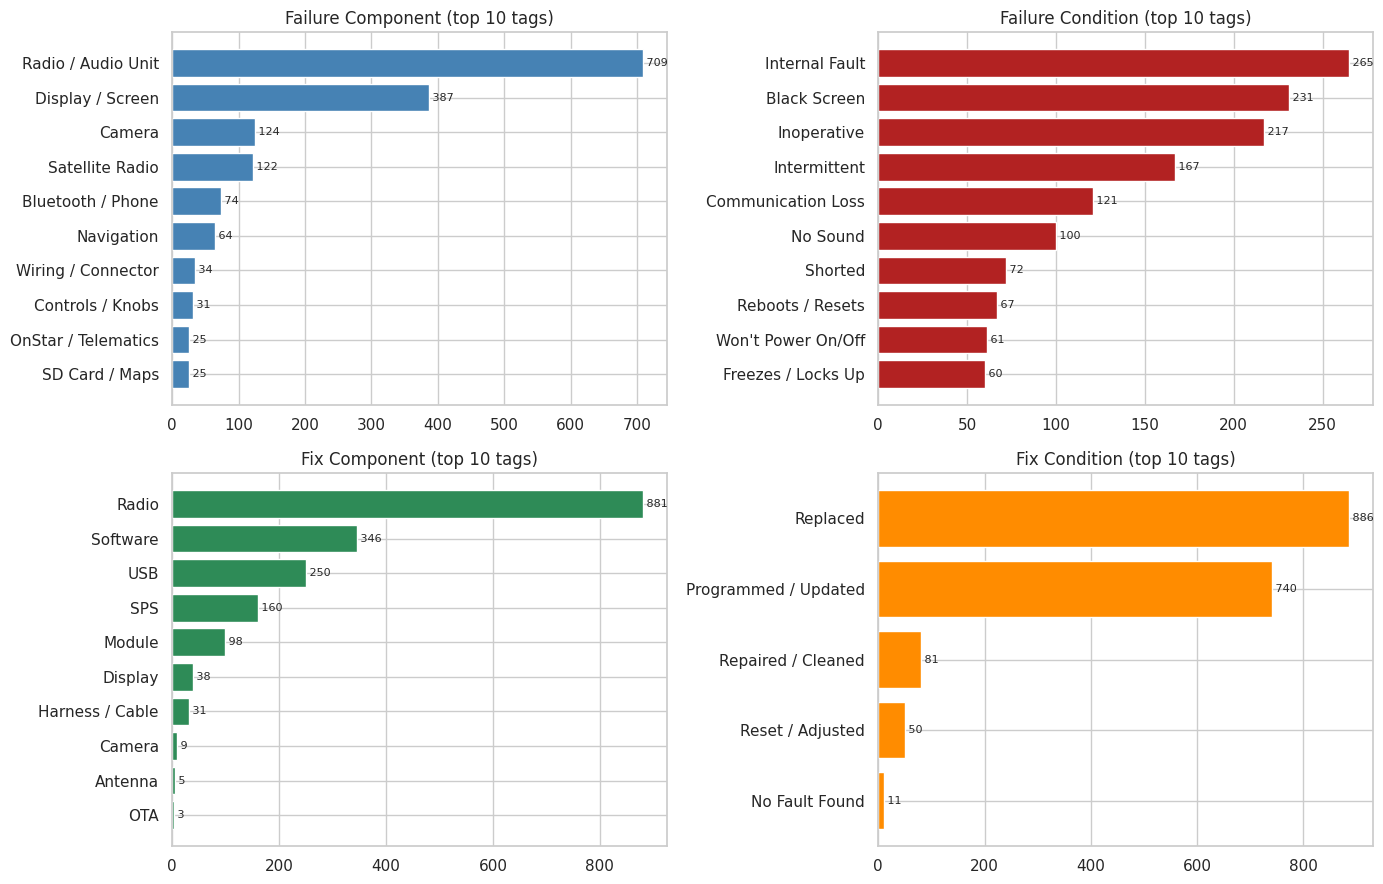

In [15]:
def explode_counts(column, drop=()):
    """Count how often each tag appears in a list-valued column."""
    counts = df[column].explode().value_counts()
    return counts[~counts.index.isin(drop)]


fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, drop, color) in zip(axes.ravel(), [
    ("Failure Component", ("Unspecified Component",), "steelblue"),
    ("Failure Condition", ("Malfunction (unspecified)",), "firebrick"),
    ("Fix Component", ("Unspecified Part",), "seagreen"),
    ("Fix Condition", ("Not Stated",), "darkorange"),
]):
    counts = explode_counts(col, drop).head(10)
    ax.barh(counts.index[::-1], counts.values[::-1], color=color)
    ax.set_title(col + " (top 10 tags)")
    for i, v in enumerate(counts.values[::-1]):
        ax.text(v, i, f" {v}", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_top_tags.png", dpi=150)
plt.show()

**Limits of the rule-based approach (be honest about these)**

* It cannot read negation or context beyond a few words, so a claim that says "radio works fine, screen is blank" may also get a radio tag.
* A symptom described with words not in the dictionary is lost. About one in five claims has no named condition and falls back to `Malfunction (unspecified)`.
* Rows in Spanish are only partly covered.
* Fix components come from the few words after a repair verb. A long note that lists several repairs can still be incomplete.

**Next step if time allowed:** keep these rules as the baseline, hand-label about 150 rows, and fine-tune a small token classifier or prompt an open-source LLM, then compare precision and recall against the rules.

## 7. Issue classification
We group the tags into higher-level issue types, using a fixed priority order so each claim gets exactly one category. The causal text and fix actions are used, not just the coded cause, so the result is a real text-mining outcome. We then cross-check against the coded cause.

| Priority | Category | Evidence |
|---|---|---|
| 1 | Assembly / Build Quality | coded cause is a loose, fastener, routing, alignment or wrong-part type |
| 2 | No Fault Found | technician could not duplicate and nothing was replaced |
| 3 | Electrical Issue | short, wiring, connector or poor contact stated in the causal text |
| 4 | Communication / Network Fault | communication or ethernet fault stated in the causal text |
| 5 | Software Glitch | causal text names software, or the fix was programming with no part replaced |
| 6 | Component Failure | causal text names an internal, faulty or failed part, or a part was replaced |
| 7 | Other / Unclassified | none of the above |

The text is checked first. The dealer's coded cause is only a fallback when the text gives no evidence, and a `Category Evidence` column records which source decided each claim. Mentions that are negated or only describe checking ("checked for software updates, none found") are ignored.

In [16]:
ASSEMBLY_CODE = r"loose|not clipped|routing|alignment|wrong part|foreign|fastener|rotating part|surface|interface|resonance|out of balance|noise during"
ELECTRICAL_TEXT = r"short|wiring|harness|connector|corrod|poor contact|open circuit|\bpin\b|terminal|water|moisture"
COMMUNICATION_TEXT = r"communicat|ethernet|network|data link|\bu\d{4}\b"
SOFTWARE_TEXT = r"software|programming|incorrect version|reflash|calibration|update"
COMPONENT_TEXT = r"internal|faulty|failed|failure|broken|damage|defective|inop"
NEGATION_CLASS = r"\b(?:no|not|unable|without|cannot|can.?t|never|if|any|checked for|check for|test(ed)? for|looking for|verify|verified)\b(?:\W+\w+){0,3}\W*$"


def positive_match(pattern, text):
    """True if the pattern appears in the text at least once without a negating or checking phrase just before it."""
    for match in re.finditer(pattern, text):
        if not re.search(NEGATION_CLASS, text[max(0, match.start() - 35):match.start()]):
            return True
    return False


def issue_category(row):
    """Give one issue category to a claim and say what evidence decided it (text, fix action or code)."""
    code_text = row["CAUSAL_CD_DESC"].lower()
    fixes = row["Fix Condition"]
    replaced = "Replaced" in fixes
    causal = row["causal"]
    if re.search(ASSEMBLY_CODE, code_text):
        return "Assembly / Build Quality", "code"
    if "No Fault Found" in fixes and not replaced:
        return "No Fault Found", "fix action"
    if positive_match(ELECTRICAL_TEXT, causal):
        return "Electrical Issue", "text"
    if positive_match(COMMUNICATION_TEXT, causal):
        return "Communication / Network Fault", "text"
    if positive_match(SOFTWARE_TEXT, causal) or ("Programmed / Updated" in fixes and not replaced):
        return "Software Glitch", "text" if positive_match(SOFTWARE_TEXT, causal) else "fix action"
    if positive_match(COMPONENT_TEXT, causal):
        return "Component Failure", "text"
    if "wiring" in code_text or "shorted" in code_text or "poor contact" in code_text:
        return "Electrical Issue", "code"
    if "communication" in code_text:
        return "Communication / Network Fault", "code"
    if "incorrect version" in code_text:
        return "Software Glitch", "code"
    if replaced:
        return "Component Failure", "fix action"
    return "Other / Unclassified", "none"


result = df.apply(issue_category, axis=1, result_type="expand")
df["Issue Category"] = result[0]
df["Category Evidence"] = result[1]
category_counts = df["Issue Category"].value_counts()
print(df["Category Evidence"].value_counts().to_string())
pd.DataFrame({"claims": category_counts, "share_pct": (category_counts / len(df) * 100).round(1)})

Category Evidence
text          627
code          252
fix action    115
none            6


,claims,share_pct
Issue Category,,
Component Failure,365,36.5
Electrical Issue,229,22.9
Communication / Network Fault,206,20.6
Software Glitch,168,16.8
Assembly / Build Quality,26,2.6
Other / Unclassified,6,0.6


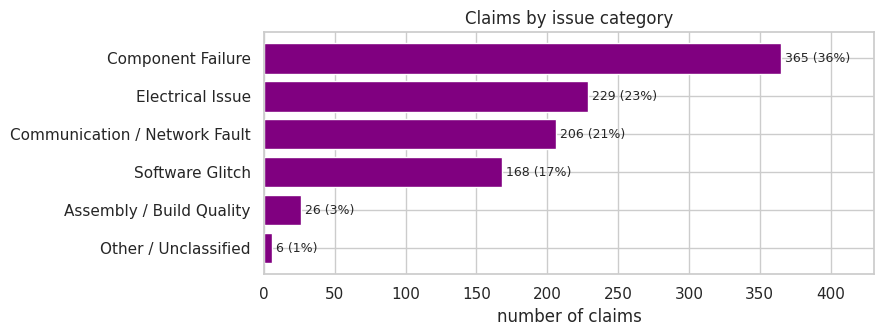

causal_group,Fastener,Interface (Gasket; Seal; Hose; Weld..),Module/Component,Other,Rotating Part,Surface (interior),Unknown,Wiring/Electrical/Sensors
Issue Category,,,,,,,,
Assembly / Build Quality,1,1,10,0,7,4,0,3
Communication / Network Fault,0,0,192,5,0,0,0,9
Component Failure,0,0,317,26,0,0,1,21
Electrical Issue,0,0,178,8,0,0,1,42
Other / Unclassified,0,0,5,1,0,0,0,0
Software Glitch,0,0,122,27,0,0,1,18


In [17]:
_ = bar_counts(df["Issue Category"], "Claims by issue category", "08_issue_category.png", color="purple")
pd.crosstab(df["Issue Category"], df["causal_group"])

**Cross-check with the coded cause.** The coded cause is the dealer's own choice from a drop-down. Where our category and the code agree we gain confidence; where they differ, the technician's own words say something the code hides.

In [18]:
pd.crosstab(df["Issue Category"], df["causal_detail"]).loc[:, lambda t: t.sum() >= 15]

causal_detail,Broken,Campaign/ Tech Bulletin,Follow operation,No trouble found - adjusted / reprogrammed,No/Incorrect Communication,Registers Incorrectly,Shorted
Issue Category,,,,,,,
Assembly / Build Quality,3,0,0,0,0,0,0
Communication / Network Fault,6,2,2,1,174,5,14
Component Failure,20,9,11,5,127,87,81
Electrical Issue,2,2,4,2,65,12,132
Other / Unclassified,2,0,0,1,0,3,0
Software Glitch,11,9,5,12,61,26,33


In [19]:
agreement = pd.DataFrame({
    "coded cause": ["Shorted", "No/Incorrect Communication"],
    "claims with this code": [(df["causal_detail"] == "Shorted").sum(), (df["causal_detail"] == "No/Incorrect Communication").sum()],
    "text agrees (percent)": [
        ((df["causal_detail"] == "Shorted") & (df["Issue Category"] == "Electrical Issue")).sum() / (df["causal_detail"] == "Shorted").sum() * 100,
        ((df["causal_detail"] == "No/Incorrect Communication") & (df["Issue Category"] == "Communication / Network Fault")).sum() / (df["causal_detail"] == "No/Incorrect Communication").sum() * 100,
    ],
}).round(0)
agreement

,coded cause,claims with this code,text agrees (percent)
0,Shorted,260,51.0
1,No/Incorrect Communication,427,41.0


The two biggest codes (`Shorted` and `No/Incorrect Communication`) agree with the technician's own words only about half the time. Many claims coded as communication problems are described by the technician as an internal failure of the radio itself. This matters because the code is what most dashboards count, so a dashboard built on the code alone would overstate communication faults.

## 8. Patterns and trends
**8.1 What fails most.** The most common single failure tags and the most common fix actions.

In [20]:
top_components = explode_counts("Failure Component", ("Unspecified Component",)).head(6)
top_conditions = explode_counts("Failure Condition", ("Malfunction (unspecified)",)).head(6)
print("Top failing components:\n", top_components.to_string(), "\n")
print("Top failure conditions:\n", top_conditions.to_string(), "\n")
replaced_share = df["Fix Condition"].map(lambda t: "Replaced" in t).mean()
program_share = df["Fix Condition"].map(lambda t: "Programmed / Updated" in t).mean()
both_share = df["Fix Condition"].map(lambda t: "Replaced" in t and "Programmed / Updated" in t).mean()
print(f"claims fixed by replacing a part: {replaced_share:.0%}")
print(f"claims involving programming or an update: {program_share:.0%}")
print(f"claims with both replacement and programming: {both_share:.0%}")
radio_replaced = df["Fix Component"].map(lambda t: "Radio" in t).mean()
print(f"claims where the radio unit is the fix component: {radio_replaced:.0%}")

Top failing components:
 Failure Component
Radio / Audio Unit    709
Display / Screen      387
Camera                124
Satellite Radio       122
Bluetooth / Phone      74
Navigation             64 

Top failure conditions:
 Failure Condition
Internal Fault        265
Black Screen          231
Inoperative           217
Intermittent          167
Communication Loss    121
No Sound              100 

claims fixed by replacing a part: 89%
claims involving programming or an update: 74%
claims with both replacement and programming: 67%
claims where the radio unit is the fix component: 88%


**8.1b When and under what circumstances.** How long vehicles ran before failing, and the triggers and contexts customers mention.

In [21]:
windows = pd.Series({
    "within 90 days": (valid["days_in_service"] <= 90).mean(),
    "within 180 days": (valid["days_in_service"] <= 180).mean(),
    "within 365 days": (valid["days_in_service"] <= 365).mean(),
    "after 365 days": (valid["days_in_service"] > 365).mean(),
}).mul(100).round(0)
print("share of claims by days in service (percent of claims with a valid in-service time)")
print(windows.to_string())
print()
print("triggers mentioned:")
print(explode_counts("Trigger", ("No Trigger Mentioned",)).to_string())
print()
print("extra context mentioned:")
print(explode_counts("Additional Context", ("No Additional Context",)).to_string())

share of claims by days in service (percent of claims with a valid in-service time)
within 90 days     21.0
within 180 days    43.0
within 365 days    75.0
after 365 days     25.0

triggers mentioned:
Trigger
When Reversing           120
At Start-up               87
Cold / Hot Weather         6
During Phone Use           6
After Software Update      4

extra context mentioned:
Additional Context
Repeat Visit                  64
While Driving                 60
Customer Evidence Provided    14
Parked / Idle                  9


**8.2 Change over time.** Monthly claims by issue category, and a check on whether the mix changes over time.

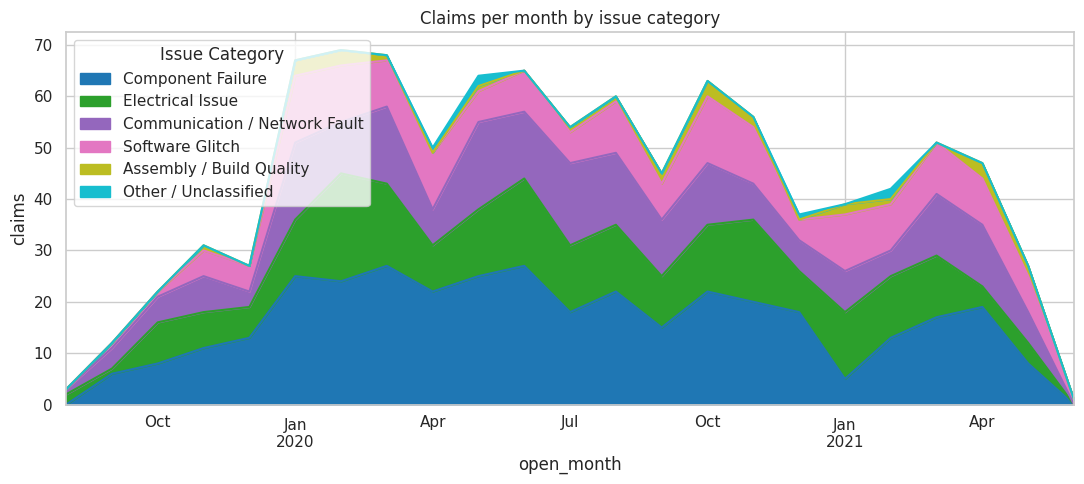

Issue Category        Assembly / Build Quality  Communication / Network Fault  Component Failure  Electrical Issue  Other / Unclassified  Software Glitch
period                                                                                                                                                   
Aug 2019 to Jun 2020                       1.9                           20.3               39.3              23.2                   0.6             14.6
Jul 2020 to Jun 2021                       3.3                           20.9               33.9              22.6                   0.6             18.8

chi-square test, is the category mix different between the two periods? p = 0.265


In [22]:
by_month = df.groupby(["open_month", "Issue Category"]).size().unstack(fill_value=0)
by_month = by_month[by_month.sum().sort_values(ascending=False).index]
by_month.plot(kind="area", stacked=True, figsize=(11, 5), colormap="tab10")
plt.title("Claims per month by issue category")
plt.ylabel("claims")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_monthly_by_category.png", dpi=150)
plt.show()

df["period"] = np.where(df["opened"] < "2020-07-01", "Aug 2019 to Jun 2020", "Jul 2020 to Jun 2021")
period_mix = pd.crosstab(df["period"], df["Issue Category"], normalize="index").mul(100).round(1)
chi2, p_value, _, _ = stats.chi2_contingency(pd.crosstab(df["period"], df["Issue Category"]))
print(period_mix.to_string())
print(f"\nchi-square test, is the category mix different between the two periods? p = {p_value:.3f}")

**8.3 How early do failures happen?** Days in service at the time of claim, by issue category. Early failures point to build or part defects; late ones point to wear.

In [23]:
timing = valid.assign(category=df.loc[valid.index, "Issue Category"]).groupby("category")["days_in_service"].agg(["count", "median", "mean"]).round(0).sort_values("count", ascending=False)
timing

,count,median,mean
category,,,
Component Failure,341,212.0,228.0
Electrical Issue,206,236.0,250.0
Communication / Network Fault,185,235.0,240.0
Software Glitch,160,234.0,258.0
Assembly / Build Quality,26,220.0,251.0
Other / Unclassified,6,254.0,302.0


In [24]:
groups = [g["days_in_service"].values for _, g in valid.assign(category=df.loc[valid.index, "Issue Category"]).groupby("category") if len(g) >= 20]
h_stat, p_timing = stats.kruskal(*groups)
print(f"Kruskal-Wallis test, does time in service differ between issue categories (groups with at least 20 claims)? p = {p_timing:.3f}")

Kruskal-Wallis test, does time in service differ between issue categories (groups with at least 20 claims)? p = 0.287


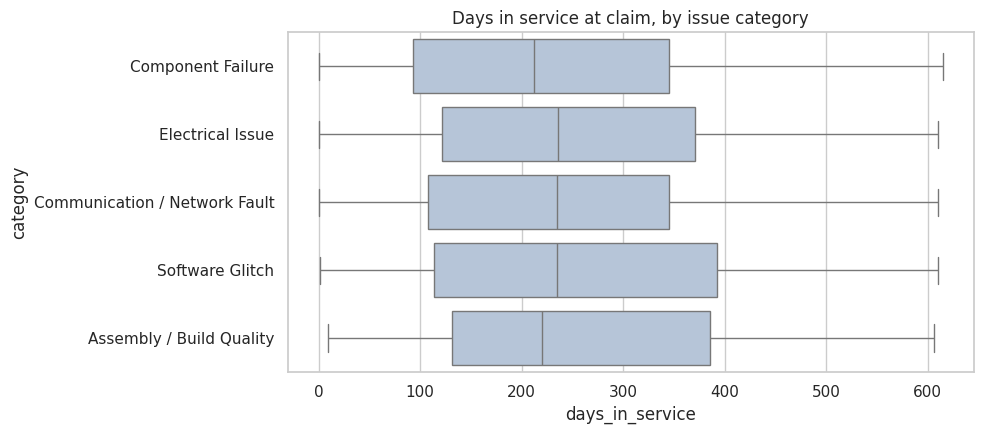

In [25]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = timing[timing["count"] >= 20].index
sns.boxplot(data=valid.assign(category=df.loc[valid.index, "Issue Category"]).query("category in @order"), y="category", x="days_in_service", order=order, ax=ax, color="lightsteelblue")
ax.set_title("Days in service at claim, by issue category")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_timing_box.png", dpi=150)
plt.show()

**8.4 Do plants or makes differ in what fails?** We have no production volumes, so we compare the *mix* of issue types inside each plant (no volume needed) and test whether the differences are bigger than chance.

share of each issue type inside plants with at least 100 claims (percent)
Issue Category       Assembly / Build Quality  Communication / Network Fault  Component Failure  Electrical Issue  Other / Unclassified  Software Glitch
BUILD_PLANT_DESC                                                                                                                                        
Flint                                     2.4                           26.0               32.7              24.0                   1.4             13.5
Fort Wayne                                4.1                           17.1               39.2              24.0                   0.5             15.2
Lansing Delta                             1.4                           23.2               32.4              21.8                   0.7             20.4
Silao                                     2.5                           16.1               38.2              26.1                   0.5             16.6
Spring H

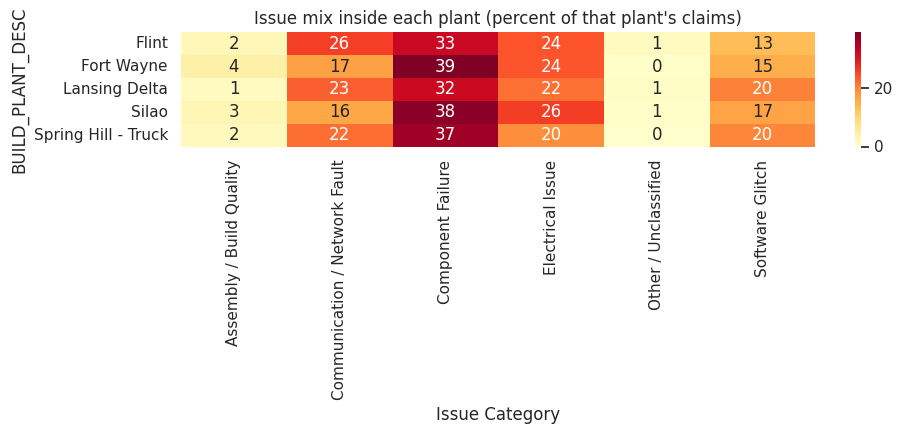

In [26]:
plant_mix = pd.crosstab(df["BUILD_PLANT_DESC"], df["Issue Category"])
big_plants = plant_mix.index[plant_mix.sum(axis=1) >= 100]
chi2_p, p_plant, _, _ = stats.chi2_contingency(plant_mix.loc[big_plants])
print("share of each issue type inside plants with at least 100 claims (percent)")
print(plant_mix.loc[big_plants].div(plant_mix.loc[big_plants].sum(axis=1), axis=0).mul(100).round(1).to_string())
print(f"\nchi-square test, does the issue mix differ by plant? p = {p_plant:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(plant_mix.loc[big_plants].div(plant_mix.loc[big_plants].sum(axis=1), axis=0).mul(100), annot=True, fmt=".0f", cmap="YlOrRd", ax=ax)
ax.set_title("Issue mix inside each plant (percent of that plant's claims)")
fig.tight_layout()
fig.savefig(FIG_DIR / "11_plant_mix.png", dpi=150)
plt.show()

## 9. Clustering to find natural failure groups
Rules only find what we thought to look for. Clustering finds groups from the words themselves.

**Method:** TF-IDF turns each note into numbers that weigh distinctive words more. K-Means groups similar notes. We test several cluster counts and use the silhouette score (higher means cleaner separation) to guide, not decide, the choice, because short repair notes overlap a lot and silhouette scores for text are always low.

We run two clusterings: customer **symptom** text (what users experience) and technician **causal** text (what the technician found wrong). Common words that appear in nearly every note (radio, replaced, programmed, customer states) are removed so the groups reflect differences, not shared wording. The repair note is left out of the root cause clustering because it mostly describes procedure steps, which would make the clusters group by writing style.

In [27]:
NOISE_WORDS = {
    "customer", "cust", "states", "state", "stated", "check", "advise", "vehicle", "concern", "customers", "reports", "report",
    "need", "needs", "per", "tac", "case", "wcc", "sop", "doc", "document", "claim", "warranty", "code", "codes", "dtc", "dtcs",
    "verified", "performed", "completed", "found", "tested", "test", "checked", "ok", "good", "operation", "operates", "time", "times",
    "radio", "replaced", "replace", "replacing", "program", "programmed", "programming", "new", "installed", "removed",
    "working", "work", "does", "doesnt", "goes",
}
STOP = list(ENGLISH_STOP_WORDS.union(NOISE_WORDS))


def run_clusters(texts, k_values, seed=42):
    """Vectorize the texts with TF-IDF, try each k with K-Means and return the matrix, the vocabulary and the silhouette per k."""
    vectorizer = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=5, max_df=0.4, sublinear_tf=True)
    matrix = vectorizer.fit_transform(texts)
    scores = {}
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(matrix)
        scores[k] = silhouette_score(matrix, model.labels_)
    return matrix, vectorizer, scores


def describe_clusters(model, vectorizer, labels, top_n=8):
    """For every cluster return its size and the highest-weighted words at its centre."""
    terms = np.array(vectorizer.get_feature_names_out())
    rows = []
    for c in range(model.n_clusters):
        top = terms[np.argsort(model.cluster_centers_[c])[::-1][:top_n]]
        rows.append({"cluster": c, "claims": int((labels == c).sum()), "top_terms": ", ".join(top)})
    return pd.DataFrame(rows).sort_values("claims", ascending=False).reset_index(drop=True)

### 9.1 Customer symptom clusters

In [28]:
X_sym, vec_sym, scores_sym = run_clusters(df["cust"], range(4, 11))
print({k: round(v, 3) for k, v in scores_sym.items()})

{4: 0.033, 5: 0.039, 6: 0.041, 7: 0.041, 8: 0.047, 9: 0.053, 10: 0.055}


In [29]:
K_SYM = 8
km_sym = KMeans(n_clusters=K_SYM, n_init=10, random_state=42).fit(X_sym)
df["symptom_cluster"] = km_sym.labels_
sym_table = describe_clusters(km_sym, vec_sym, km_sym.labels_)
sym_table

,cluster,claims,top_terms
0,1,466,"screen, turn, shut, display, message, navigation, start, stays"
1,5,115,"xm, sound, signal, stations, play, change, loading, fm"
2,6,95,"camera, backup camera, backup, rear, reverse, screen, black, red"
3,4,85,"blank, screen, screen blank, display, audio, start, come, sound"
4,2,74,"black, screen black, screen, display, black screen, going black, sound, driving"
5,7,69,"phone, bluetooth, volume, calls, connect, blue tooth, tooth, blue"
6,3,57,"inop, screen inop, camera inop, camera, screen, display inop, display, auto"
7,0,39,"audio, audio entertainment, entertainment navigation, entertainment, navigat..."


We chose 8 clusters: the silhouette score keeps rising slowly up to 10, and 8 gives groups that a person can name without splitting them into tiny pieces. Silhouette scores are low (as expected for short text), so treat the groups as useful themes, not hard boundaries. Reading the top terms of each group:

In [30]:
sym_names = {}
for _, r in sym_table.iterrows():
    sym_names[r["cluster"]] = "Symptom " + str(r["cluster"]) + ": " + " / ".join(r["top_terms"].split(", ")[:3])
df["Symptom Cluster"] = df["symptom_cluster"].map(sym_names)
cross = pd.crosstab(df["Symptom Cluster"], df["Issue Category"])
cross

Issue Category,Assembly / Build Quality,Communication / Network Fault,Component Failure,Electrical Issue,Other / Unclassified,Software Glitch
Symptom Cluster,,,,,,
Symptom 0: audio / audio entertainment / entertainment navigation,0,7,12,10,1,9
Symptom 1: screen / turn / shut,15,100,158,105,3,85
Symptom 2: black / screen black / screen,3,11,34,16,0,10
Symptom 3: inop / screen inop / camera inop,1,9,25,16,0,6
Symptom 4: blank / screen / screen blank,0,17,32,29,0,7
Symptom 5: xm / sound / signal,1,23,46,18,2,25
Symptom 6: camera / backup camera / backup,4,24,37,20,0,10
Symptom 7: phone / bluetooth / volume,2,15,21,15,0,16


### 9.2 Technician cause clusters (root cause view)

In [31]:
df["cause_text"] = df["causal"].str.slice(0, 700)
X_root, vec_root, scores_root = run_clusters(df["cause_text"], range(4, 11))
print({k: round(v, 3) for k, v in scores_root.items()})

{4: 0.081, 5: 0.076, 6: 0.083, 7: 0.088, 8: 0.093, 9: 0.102, 10: 0.1}


In [32]:
K_ROOT = 8
km_root = KMeans(n_clusters=K_ROOT, n_init=10, random_state=42).fit(X_root)
df["root_cluster"] = km_root.labels_
root_table = describe_clusters(km_root, vec_root, km_root.labels_, top_n=10)
root_table

,cluster,claims,top_terms
0,6,567,"module, internal, screen, power, display, faulty, diag, short, camera, ground"
1,7,104,"update, usb, software, contacted, advised, software update, air, sps, na, tried"
2,1,80,"communication, lost communication, lost, module, incorrect communication, in..."
3,4,79,"fault, internal fault, internal, scan, scan internal, scan update, module, f..."
4,3,61,"failure, internal failure, internal, communication, module, causing, loss, e..."
5,0,57,"replacement, date, software, stored, software date, scanned, contacted, advi..."
6,5,28,"shorted, internally, shorted internally, internally shorted, module, connect..."
7,2,24,"malfunction, internal malfunction, internal, testing, diag, circuit, xm, mod..."


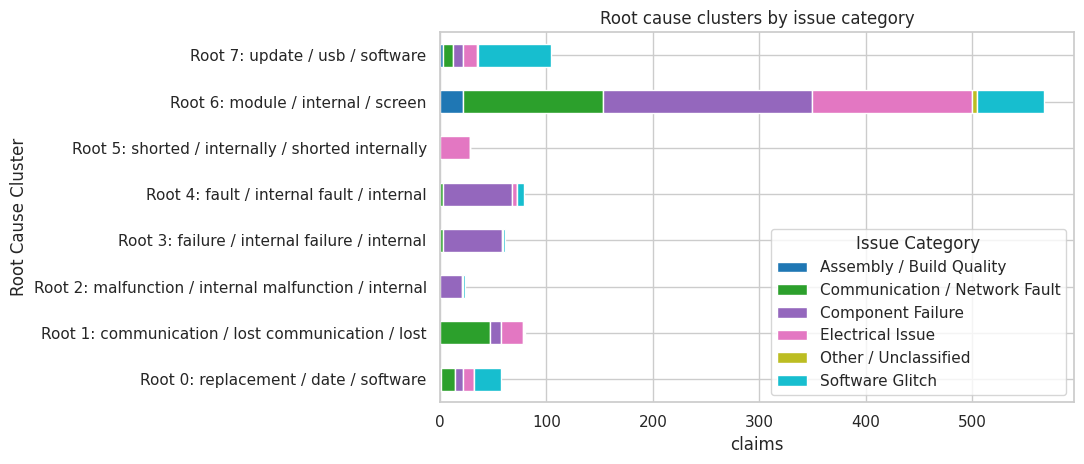

,claims,median_days_in_service,pct_replaced,pct_programmed
Root Cause Cluster,,,,
Root 6: module / internal / screen,567,231.0,87.0,72.0
Root 7: update / usb / software,104,263.0,81.0,77.0
Root 1: communication / lost communication / lost,80,279.0,91.0,80.0
Root 4: fault / internal fault / internal,79,176.5,97.0,65.0
Root 3: failure / internal failure / internal,61,204.0,95.0,72.0
Root 0: replacement / date / software,57,170.0,95.0,89.0
Root 5: shorted / internally / shorted internally,28,304.0,89.0,82.0
Root 2: malfunction / internal malfunction / internal,24,199.5,96.0,88.0


In [33]:
root_names = {}
for _, r in root_table.iterrows():
    root_names[r["cluster"]] = "Root " + str(r["cluster"]) + ": " + " / ".join(r["top_terms"].split(", ")[:3])
df["Root Cause Cluster"] = df["root_cluster"].map(root_names)

fig, ax = plt.subplots(figsize=(11, 4.8))
pd.crosstab(df["Root Cause Cluster"], df["Issue Category"]).plot(kind="barh", stacked=True, ax=ax, colormap="tab10")
ax.set_title("Root cause clusters by issue category")
ax.set_xlabel("claims")
fig.tight_layout()
fig.savefig(FIG_DIR / "12_root_clusters.png", dpi=150)
plt.show()

summary_cols = ["Failure Component", "Fix Condition"]
root_profile = pd.DataFrame({
    "claims": df.groupby("Root Cause Cluster").size(),
    "median_days_in_service": valid.groupby(df.loc[valid.index, "Root Cause Cluster"])["days_in_service"].median(),
    "pct_replaced": df.groupby("Root Cause Cluster")["Fix Condition"].apply(lambda s: s.map(lambda t: "Replaced" in t).mean() * 100).round(0),
    "pct_programmed": df.groupby("Root Cause Cluster")["Fix Condition"].apply(lambda s: s.map(lambda t: "Programmed / Updated" in t).mean() * 100).round(0),
}).sort_values("claims", ascending=False)
root_profile

In [34]:
root_groups = [g["days_in_service"].values for _, g in valid.assign(cluster=df.loc[valid.index, "Root Cause Cluster"]).groupby("cluster") if len(g) >= 20]
h_root, p_root = stats.kruskal(*root_groups)
print(f"Kruskal-Wallis test, does time in service differ between root cause clusters? p = {p_root:.4f}")

Kruskal-Wallis test, does time in service differ between root cause clusters? p = 0.0775


In [35]:
for cluster_name in root_profile.index[:6]:
    print(cluster_name)
    sample = df[df["Root Cause Cluster"] == cluster_name].sample(2, random_state=3)
    for text in sample["causal"]:
        print("   cause note:", text[:200])
    print()

Root 6: module / internal / screen
   cause note: diag and found internal short in radio display causing camera issues. ness to replace radio display
   cause note: mary lawson purchased in clean up . - tac case chk power/gnd-

Root 7: update / usb / software
   cause note: verified concern/found radio unresponsive,would no communicate.contacted tac. case # - .tac advised replace radio
   cause note: technician was able to duplicate customer concern stations on xm radio will play for maybe seconds then pause change called t.a.ccase # - was advised to update radio software-in concern is not fixed w

Root 1: communication / lost communication / lost
   cause note: - lost communication with instrument cluster on low speed can bus.checked fuses & info right fuse block both goodradio loosing communication in & out.
   cause note: internal radio connection issue, no communication, no codes set, softw are up to date, tech case - replace radio

Root 4: fault / internal fault / internal
   caus

## 10. Root causes and findings
The printed numbers above are the evidence. The stakeholder report (`Task2_Stakeholder_Report.docx`) interprets them in business language. The checks that every finding has to pass:

* **Is it counted or inferred?** Counts come from the tags. Anything about *why* is an interpretation of cluster terms and is marked as such.
* **Is it a rate or a count?** There are no production volumes, so plant, model and make differences are counts only. Mix comparisons are used where possible.
* **Is it one cohort?** All vehicles were built in one 5-week window, so build-date effects cannot be separated from plant effects.

In [36]:
facts = {
    "total claims": len(df),
    "share fixed by replacing a part": f"{replaced_share:.0%}",
    "share with programming or update": f"{program_share:.0%}",
    "median days in service at claim": int(valid["days_in_service"].median()),
    "claims opened before in-use date (flagged)": int(df["opened_before_in_use"].sum()),
    "top issue category": category_counts.index[0] + f" ({category_counts.iloc[0]} claims)",
    "second issue category": category_counts.index[1] + f" ({category_counts.iloc[1]} claims)",
}
pd.Series(facts).to_frame("value")

,value
total claims,1000
share fixed by replacing a part,89%
share with programming or update,74%
median days in service at claim,228
claims opened before in-use date (flagged),76
top issue category,Component Failure (365 claims)
second issue category,Electrical Issue (229 claims)


## 11. Export the tagged dataset
The export keeps every original column, adds the six tag columns in the same list format as the example rows, the issue category, both cluster labels and the helper flags. It is saved as CSV and Excel.

In [37]:
export_cols = (
    list(raw.columns[:20])
    + ["Issue Category", "Category Evidence", "Symptom Cluster", "Root Cause Cluster"]
    + ["causal_group", "causal_detail", "days_build_to_in_use", "days_in_service", "days_since_build",
       "opened_before_in_use", "in_use_imputed", "causal_code_missing"]
)
export = df[export_cols].copy()
for col in tag_cols:
    export[col] = export[col].map(lambda items: str(items))
export["Opened date"] = df["opened"].dt.strftime("%Y-%m-%d")
export["BUILD_DATE"] = df["built"].dt.strftime("%Y-%m-%d")
export["IN_USE_DATE"] = df["in_use"].dt.strftime("%Y-%m-%d")

export.to_csv(OUT_DIR / "task2_tagged_dataset.csv", index=False)
export.to_excel(OUT_DIR / "task2_tagged_dataset.xlsx", index=False)
print("saved", len(export), "rows and", export.shape[1], "columns to", OUT_DIR)
export[["Event id", "Failure Component", "Failure Condition", "Fix Component", "Fix Condition", "Issue Category"]].head(5)

saved 1000 rows and 32 columns to outputs


,Event id,Failure Component,Failure Condition,Fix Component,Fix Condition,Issue Category
0,D-14801,"['Radio / Audio Unit', 'Display / Screen', 'Other Module']","['Inoperative', 'Internal Fault', 'Communication Loss']","['Radio', 'Software', 'USB', 'SPS', 'OTA', 'Display']","['Replaced', 'Programmed / Updated', 'Reset / Adjusted']",Communication / Network Fault
1,D-14869,['Radio / Audio Unit'],"['Inoperative', 'Communication Loss']",['Radio'],"['Replaced', 'Programmed / Updated']",Electrical Issue
2,D-14555,"['Radio / Audio Unit', 'Display / Screen', 'OnStar / Telematics', 'Other Mod...",['Communication Loss'],['Unspecified Part'],['Not Stated'],Communication / Network Fault
3,D-14704,['Unspecified Component'],['Black Screen'],['Unspecified Part'],['Not Stated'],Communication / Network Fault
4,D-15142,"['Radio / Audio Unit', 'Display / Screen', 'Satellite Radio']",['Malfunction (unspecified)'],"['Radio', 'Antenna', 'Software']","['Replaced', 'Programmed / Updated']",Component Failure


## 12. Key learnings and what to improve
* Rule-based tagging is fast and explainable but misses unusual wording. A hand-labelled sample would let us measure precision and recall and decide whether an LLM tagger is worth the cost.
* The technician notes are noisy: they list steps that were checked as well as faults. Reading each part only near a repair verb removed a lot of false tags.
* Redacted numbers mean fault codes (DTCs) cannot be mined. Keeping the codes in the source data would unlock a much stronger root cause analysis.
* Without production volumes we cannot compute failure rates by plant or model. Adding vehicles built per plant and model would turn counts into rates.
* A proper warranty analysis would use months-in-service survival curves, which needs the count of vehicles still in service without a claim.